# TF Footprinting

A transcription factor bound to DNA shields the few base pairs under it from
Tn5, which leaves a dip in the insertion profile flanked by accessible DNA: a
footprint. [TOBIAS](https://github.com/loosolab/TOBIAS) (Bentsen et al.,
*Nat Commun* 2020) corrects the Tn5 sequence bias of the cut sites, scores
footprints, and compares TF binding between conditions.

`gatac.tobias` runs the TOBIAS pipeline on the GPU, reading cut sites straight
from the fragments Parquet, with no BAM or bigwig files:

| GATAC | TOBIAS | |
|---|---|---|
| `footprint` | `ATACorrect` + `ScoreBigwig` | Tn5 bias correction and footprint scores per pseudobulk |
| `bindetect_sites` | (inside `BINDetect`) | motif binding sites in the peaks, built once |
| `bindetect` | `BINDetect` | footprint score per site, bound sites, differential binding |

Given the same inputs, every stage matches TOBIAS 0.17.5; the
[reproducibility](https://github.com/Soldatov-Lab/gatac-reproducibilty)
tests check it stage by stage. This notebook starts from the fragments Parquet
of [01](01_fragment_preprocessing.ipynb) and the peaks and cell types of
[02](02_embedding_peak_calling.ipynb).

## Setup

Download a **MEME motif database file** containing human transcription factor binding motifs from the Cis-BP resource, alongside the **human genome** in fasta format.

In [1]:
%%bash
[ -f data/cisBP_human.meme ] || wget -O data/cisBP_human.meme https://osf.io/download/uk6vn
[ -f data/GRCh38.fa ] || wget -O data/GRCh38.fa.gz https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_38/GRCh38.p13.genome.fa.gz
[ -f data/GRCh38.fa ] || gunzip -c data/GRCh38.fa.gz > data/GRCh38.fa

In [2]:
import time

import anndata as ad
import matplotlib.pyplot as plt

import gatac as ga

GENOME_FASTA = "data/GRCh38.fa"
MOTIF_FILE   = "data/cisBP_human.meme"
PARQUET      = "data/pbmc_fragments.parquet"

peak_adata = ad.read_h5ad("data/pbmc_peaks.h5ad")
print(peak_adata)
peak_adata.obs["cell_type"].value_counts()

AnnData object with n_obs × n_vars = 5001 × 179702
    obs: 'barcode', 'source_file', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden', 'cell_type'
    obsm: 'X_umap'


cell_type
CD14 Mono    1562
CD4 T        1411
CD8 T         832
B             477
Other         320
NK            279
DC            120
Name: count, dtype: int64

## 1. Bias correction and footprint scores

Footprinting needs depth, so it works on pseudobulks: here three lineages from
the cell types of notebook 02, one myeloid, one B and one T. For each, `footprint`

1. learns the Tn5 insertion bias of that pseudobulk from the cut sites outside
   peaks,
2. corrects the cut sites in the peaks for it, and
3. scores every position of the peaks for a footprint: depletion at the centre
   relative to the flanks.

The peaks are the union peak set of notebook 02 (`peak_adata.var_names`), as
TOBIAS recommends. Genome-wide, this step takes a few minutes per pseudobulk;
`chromosomes=["chr19"]` gives a quick first run.

In [3]:
GROUPS = ["CD14 Mono", "B", "CD4 T"]

t0 = time.perf_counter()
tracks = ga.tobias.footprint(
    peak_adata,
    groupby="cell_type",
    parquet_path=PARQUET,
    genome_fasta=GENOME_FASTA,
    groups=GROUPS,
)
print(f"Footprinting in {time.perf_counter() - t0:.1f}s")
tracks.stats

Bias model:   0%|          | 0/24 [00:00<?, ?it/s]

Correct + footprint:   0%|          | 0/24 [00:00<?, ?it/s]

11:13:57 - gatac.tobias.footprint - INFO - footprint timings: load 121.6s, bias_model 25.2s, correct_footprint 353.3s


Footprinting in 505.8s


,n_cells,reads_total,reads_peaks,frip,correction_factor,windows_fit,windows_no_signal,windows_fallback
group,,,,,,,,
CD14 Mono,1562,53636620,32533245,0.606549,0.307378,17101588,8126312,12762
B,477,12884022,8397328,0.651763,1.190855,9878184,15352126,10352
CD4 T,1411,37273990,22970836,0.616270,0.435335,12350477,12878581,11604


`reads_peaks` and `frip` describe each pseudobulk's signal;
`correction_factor` (10 million divided by `reads_peaks`) scales the corrected
tracks to a common depth. The bias correction is fitted in windows along the
peaks: `windows_no_signal` have no cut sites, and `windows_fallback` are the
few where the fit fails and TOBIAS's fallback is used.

## 2. Differential binding

`bindetect_sites` scans the peaks for every motif and keeps the binding sites;
they depend only on the peaks and motifs, so one site set serves every set of
pseudobulks footprinted on the same peaks. `bindetect` then reads the footprint
score at each site, calls sites bound, and tests every pair of groups for
differential binding of each TF.

We use one motif per TF (`unique=True`), as in notebooks 03–05. To reproduce
TOBIAS exactly, pass the MEME path instead: TOBIAS reads the raw matrices and
`nsites` from the file.

In [4]:
motifs = ga.motif.read(MOTIF_FILE, unique=True)
print(f"Loaded {len(motifs)} motifs")

t0 = time.perf_counter()
sites = ga.tobias.bindetect_sites(tracks, motifs)
print(f"{len(sites.start):,} binding sites in {time.perf_counter() - t0:.1f}s")

t0 = time.perf_counter()
res = ga.tobias.bindetect(tracks, sites=sites)
print(f"BINDetect in {time.perf_counter() - t0:.1f}s")
print("Comparisons:", res.comparisons)

Loaded 1165 motifs


11:14:14 - gatac.tobias.bindetect - INFO - bindetect_sites timings: layout 4.9s, motifs 3.7s, scan 5.0s, resolve 1.2s, overlaps 0.2s, order 0.6s


32,013,839 binding sites in 16.2s


11:15:24 - gatac.tobias.bindetect - INFO - bindetect timings: footprints 0.5s, background 3.6s, site_table 3.3s, per_tf 61.5s, clusters 0.1s, total 69.0s


BINDetect in 69.5s
Comparisons: [('CD14 Mono', 'B'), ('CD14 Mono', 'CD4 T'), ('B', 'CD4 T')]


`res.results` has one row per motif, with the columns of TOBIAS's
`bindetect_results.txt`: the mean footprint score and number of bound sites per
group, and for each comparison a differential binding score (`change`), its
p-value, and whether the TF stands out (`highlighted`). The TFs with the
largest gain in monocytes over B cells:

In [5]:
cols = ["name", "total_tfbs", "CD14 Mono_mean_score", "B_mean_score",
        "CD14 Mono_B_change", "CD14 Mono_B_pvalue"]
res.results.nlargest(10, "CD14 Mono_B_change")[cols]

,name,total_tfbs,CD14 Mono_mean_score,B_mean_score,CD14 Mono_B_change,CD14 Mono_B_pvalue
64,CEBPG,9436,0.50738,0.13233,0.92133,1.331899e-195
62,CEBPD,11665,0.48875,0.12318,0.91017,1.208150e-198
63,CEBPE,9566,0.53758,0.16101,0.90007,2.436537e-194
61,CEBPB,15434,0.45007,0.11496,0.82536,6.198614e-199
60,CEBPA,31733,0.35899,0.09435,0.65857,2.329752e-204
758,TEF,10453,0.38502,0.12054,0.65382,4.550424e-179
285,HLF,11596,0.38508,0.14229,0.56453,3.801796e-178
374,JUNB,14934,0.45921,0.15711,0.51115,5.892128e-178
487,NFE2L1,17024,0.45112,0.16873,0.48850,3.972755e-183
175,FOS,22250,0.41509,0.13908,0.48276,2.840074e-185


## 3. Volcano plots

One panel per comparison: differential binding score against significance.
Highlighted TFs are the 5% largest changes on each side or the most
significant; the strongest are labelled.

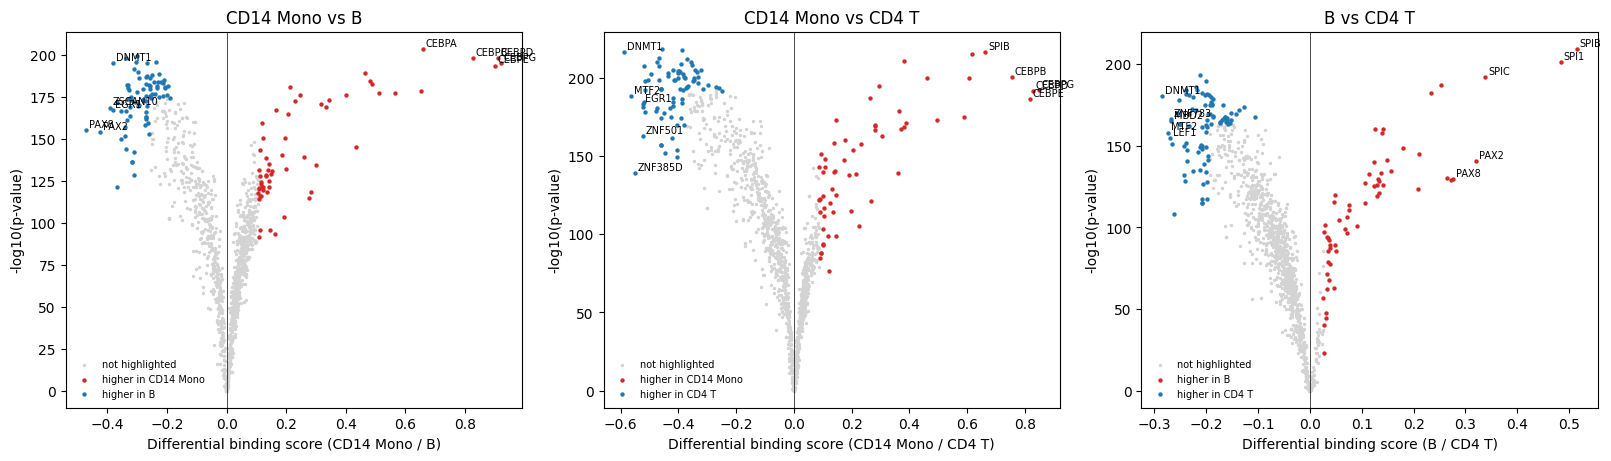

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, (g1, g2) in zip(axes, res.comparisons):
    ga.pl.bindetect_volcano(res, g1, g2, ax=ax)
    ax.set_title(f"{g1} vs {g2}")
plt.show()

The lineage factors come out without any prior: C/EBP family members in
monocytes against both lymphoid lineages, the ETS factors SPI1 (PU.1) and SPIB
in monocytes and B cells against T cells, and LEF1/TCF in T cells.

## 4. Aggregate footprints

Averaging the corrected Tn5 signal over all binding sites of a motif, centred
and oriented on the motif, shows the footprint itself. CTCF, bound in every
cell type, gives a deep footprint in all three; the lineage factors differ
between pseudobulks.

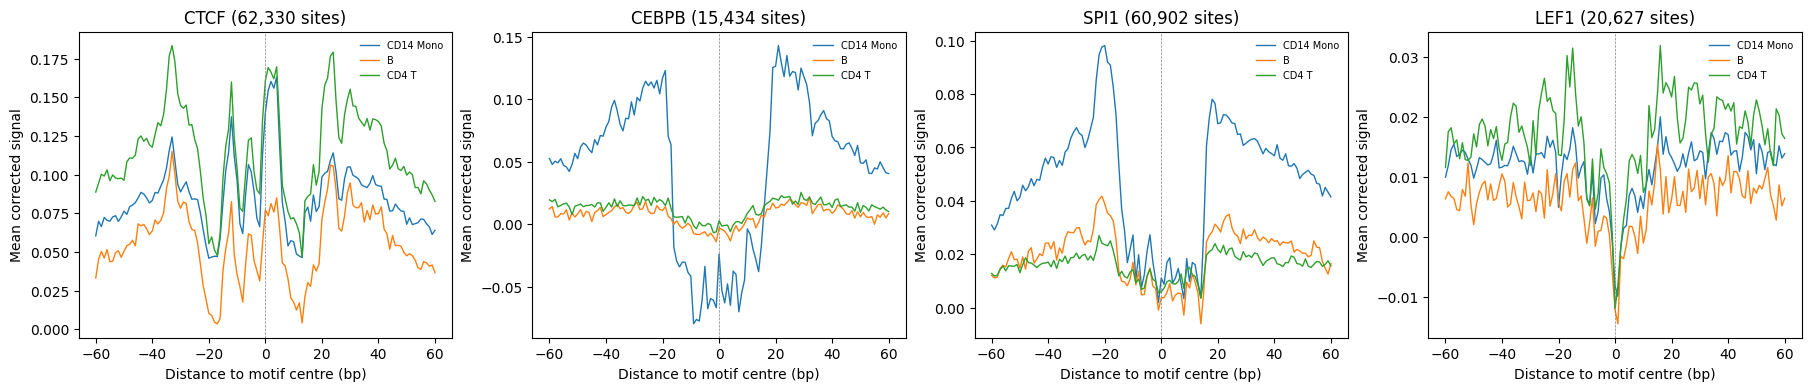

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), constrained_layout=True)
for ax, tf in zip(axes, ["CTCF", "CEBPB", "SPI1", "LEF1"]):
    ga.pl.footprint_aggregate(tracks, res, tf, ax=ax)
plt.show()

## Notes

- **Time and memory.** Genome-wide footprinting of three pseudobulks takes
  about 9 minutes on an RTX 5070 (12 GB), and this notebook peaks at about
  10 GB of host memory. Fewer pseudobulks or `chromosomes=` reduce both.
- **Reusing sites.** Pass the same `sites` to `bindetect` for another set of
  pseudobulks footprinted on the same peaks, e.g. other cell types or
  conditions.
- **TOBIAS quirks.** `tobias_compat=True` (the default) reproduces TOBIAS
  exactly, quirks included; `tobias_compat=False` fixes them. See the
  [`gatac.tobias` API](../docs/api/tobias.md).

## Next steps

- [API: `gatac.tobias`](../docs/api/tobias.md)